# 07 — Model Comparison and Leaderboard

This notebook:
1. Loads all predictions from NB04–06
2. Builds a complete leaderboard (sorted by test RMSE)
3. Reports paired Wilcoxon tests vs B2 and vs predict-0
4. Plots per-creator RMSE distribution and stratified win-rates
5. Re-trains top-3 models with 5 seeds to measure variance
6. Saves `results/leaderboard.csv`

In [1]:
import os, time, warnings
from pathlib import Path

if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir(os.path.dirname(os.getcwd()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import joblib
warnings.filterwarnings("ignore")

from creator_analytics import features as fe
from creator_analytics.config import load_config
from creator_analytics.evaluate import (
    compute_metrics, compute_per_creator_metrics,
    paired_comparison, log_experiment,
)

cfg       = load_config("config/default.yaml")
PROCESSED = Path(cfg["paths"]["processed_dir"])
PREDS_DIR = Path("results/predictions")
FIGS      = Path("results/figures"); FIGS.mkdir(parents=True, exist_ok=True)
SEED      = cfg["seed"]
TODAY     = "2026-10-25"


In [2]:
data, spec = fe.load_feature_table(PROCESSED)
idx  = pd.read_parquet(PROCESSED / "dataset_index.parquet")
TEST = idx["split"].eq("test")
auth_test = idx.loc[TEST, "author_id"].reset_index(drop=True)

# Load all predictions
nb04 = pd.read_parquet(PREDS_DIR / "nb04_predictions.parquet")
nb05 = pd.read_parquet(PREDS_DIR / "nb05_predictions.parquet")
nb06 = pd.read_parquet(PREDS_DIR / "nb06_predictions.parquet")

y_test = nb04["y_true"]
zero_preds = np.zeros(len(y_test))

META = ["video_id", "author_id", "y_true"]
# NB06 includes B2_global_XGB as baseline reference — skip it to avoid duplicate
preds_cols_04 = [c for c in nb04.columns if c not in META]
preds_cols_05 = [c for c in nb05.columns if c not in META]
preds_cols_06 = [c for c in nb06.columns if c not in META and c != "B2_global_XGB"]

all_preds = {}
for df, cols in [(nb04, preds_cols_04), (nb05, preds_cols_05), (nb06, preds_cols_06)]:
    for c in cols:
        all_preds[c] = df[c].values

print(f"Models loaded: {list(all_preds.keys())}")


Models loaded: ['A1_zero', 'A2_creator_mean', 'B1_RF', 'B2_XGB', 'B3_RF_pc', 'B4_XGB_pc', 'C1_global_LGBM', 'C2_global_Ridge', 'C1_perCreator_LGBM', 'C2_perCreator_Ridge', 'C3_shrinkage', 'C4_finetune_XGB', 'C5_two_stage', 'C6_cluster', 'C7_mixed_effects']


## Leaderboard

In [3]:
b2_preds = all_preds["B2_XGB"]
b1_preds = all_preds["B1_RF"]
rows = []
for name, preds in all_preds.items():
    nan_n = int(np.isnan(preds).sum())
    preds_c = preds.copy()
    if nan_n > 0:
        preds_c[np.isnan(preds_c)] = b2_preds[np.isnan(preds_c)]
    m = compute_metrics(y_test, preds_c)
    cmp_b2   = paired_comparison(y_test, preds_c, b2_preds, auth_test, name, "B2_XGB")
    cmp_zero = paired_comparison(y_test, preds_c, zero_preds, auth_test, name, "predict-0")
    rows.append({
        "model": name,
        "rmse": m["rmse"], "mae": m["mae"], "r2": m["r2"], "spearman": m["spearman"],
        "vs_B2_diff": cmp_b2["rmse_diff"],
        "vs_B2_p": cmp_b2["wilcoxon_pvalue"],
        "vs_B2_win": round(cmp_b2["win_rate_a"], 3),
        "vs_zero_diff": cmp_zero["rmse_diff"],
        "vs_zero_p": cmp_zero["wilcoxon_pvalue"],
        "nan_preds": nan_n,
    })

leaderboard = pd.DataFrame(rows).sort_values("rmse").reset_index(drop=True)
leaderboard.index += 1  # rank starts at 1
display(leaderboard.round(4))
leaderboard.to_csv("results/leaderboard.csv", index_label="rank")
print("Saved results/leaderboard.csv")


,model,rmse,mae,r2,spearman,vs_B2_diff,vs_B2_p,vs_B2_win,vs_zero_diff,vs_zero_p,nan_preds
1,B3_RF_pc,0.8872,0.5612,0.1968,0.3925,-0.0255,0.0000,0.542,-0.1133,0.0000,0
2,C5_two_stage,0.8905,0.5676,0.1907,0.3985,-0.0221,0.0000,0.533,-0.1099,0.0000,0
3,B4_XGB_pc,0.8967,0.5672,0.1794,0.3897,-0.0159,0.0000,0.534,-0.1037,0.0000,0
4,C4_finetune_XGB,0.9046,0.5930,0.1649,0.3687,-0.0081,0.0000,0.484,-0.0959,0.8763,0
5,C3_shrinkage,0.9089,0.5821,0.1569,0.3208,-0.0037,0.0000,0.617,-0.0915,0.0000,0
6,C1_global_LGBM,0.9104,0.5841,0.1541,0.3198,-0.0022,0.0027,0.507,-0.0900,0.0000,0
7,B1_RF,0.9113,0.5789,0.1525,0.3264,-0.0014,0.0000,0.525,-0.0892,0.0000,0
8,C6_cluster,0.9121,0.5850,0.1509,0.3020,-0.0005,0.8196,0.502,-0.0883,0.0000,0
9,B2_XGB,0.9127,0.5855,0.1499,0.3101,0.0000,NaN,0.000,-0.0878,0.0000,0
10,C1_perCreator_LGBM,0.9219,0.5923,0.1327,0.3553,0.0092,0.0023,0.498,-0.0786,0.6523,0


Saved results/leaderboard.csv


In [4]:
# === Same-algorithm comparisons ===
# Win-rate = fraction of TEST VIDEOS where |err_A| < |err_B| (strict <).
# Ties count as non-wins for A; with continuous predictions, true ties are negligible.
# Per-CREATOR win rate (fraction of creators where A_RMSE < B_RMSE) is reported
# separately — it differs from per-video because it does not weight by video count.
#
# Why 53.4% ≠ 55.0% for B4 vs B2:
#   53.4% = per-video win rate  (each of the 40,124 test videos counts equally)
#   55.0% = per-creator win rate (each of the 1,437 creators counts equally)
# Large creators contribute more videos, so the two metrics can diverge.

print("=== Same-algorithm paired comparisons ===")
print("  B3 vs B1 (both RF)  : fair personalisation comparison for RF")
print("  B4 vs B2 (both XGB) : fair personalisation comparison for XGB")
print("  B3 vs B2 (RF vs XGB): MIXED — conflates personalisation with algorithm")
print()

_same_algo = [
    ("B3_RF_pc",  all_preds["B3_RF_pc"],  "B1_RF",  b1_preds),
    ("B4_XGB_pc", all_preds["B4_XGB_pc"], "B2_XGB", b2_preds),
]
for name_a, pa, name_b, pb in _same_algo:
    cmp = paired_comparison(y_test, pa, pb, auth_test, name_a, name_b)
    print(f"  {name_a} vs {name_b}")
    print(f"    RMSE_diff = {cmp['rmse_diff']:+.4f}   p = {cmp['wilcoxon_pvalue']:.4f}   "
          f"win (per-video) = {cmp['win_rate_a']:.3f}")
    print(f"    Bootstrap 95% CI: [{cmp['bootstrap_ci_low']:.4f}, {cmp['bootstrap_ci_high']:.4f}]")

    # Per-creator win rate
    from creator_analytics.evaluate import compute_per_creator_metrics
    pc_a = compute_per_creator_metrics(y_test, pd.Series(pa, index=y_test.index), auth_test)
    pc_b = compute_per_creator_metrics(y_test, pd.Series(pb, index=y_test.index), auth_test)
    merged = (pc_a.set_index("author_id")["rmse"]
                  .to_frame("a")
                  .join(pc_b.set_index("author_id")["rmse"].rename("b")))
    pc_win = (merged["a"] < merged["b"]).mean()
    print(f"    Per-creator win rate: {pc_win:.3f}")

    print(f"    Per-creator median RMSE: {name_a}={pc_a['rmse'].median():.4f}  "
          f"{name_b}={pc_b['rmse'].median():.4f}")
    print(f"    Per-creator median Spearman: {name_a}={pc_a['spearman'].median():.4f}  "
          f"{name_b}={pc_b['spearman'].median():.4f}")
    print()


=== Same-algorithm paired comparisons ===
  B3 vs B1 (both RF)  : fair personalisation comparison for RF
  B4 vs B2 (both XGB) : fair personalisation comparison for XGB
  B3 vs B2 (RF vs XGB): MIXED — conflates personalisation with algorithm



  B3_RF_pc vs B1_RF
    RMSE_diff = -0.0241   p = 0.0000   win (per-video) = 0.528
    Bootstrap 95% CI: [-0.0281, -0.0202]


    Per-creator win rate: 0.584
    Per-creator median RMSE: B3_RF_pc=0.7037  B1_RF=0.7226
    Per-creator median Spearman: B3_RF_pc=0.3575  B1_RF=0.2925



  B4_XGB_pc vs B2_XGB
    RMSE_diff = -0.0159   p = 0.0000   win (per-video) = 0.534
    Bootstrap 95% CI: [-0.0207, -0.0110]


    Per-creator win rate: 0.550
    Per-creator median RMSE: B4_XGB_pc=0.7109  B2_XGB=0.7258
    Per-creator median Spearman: B4_XGB_pc=0.3333  B2_XGB=0.2580



## Visual comparison

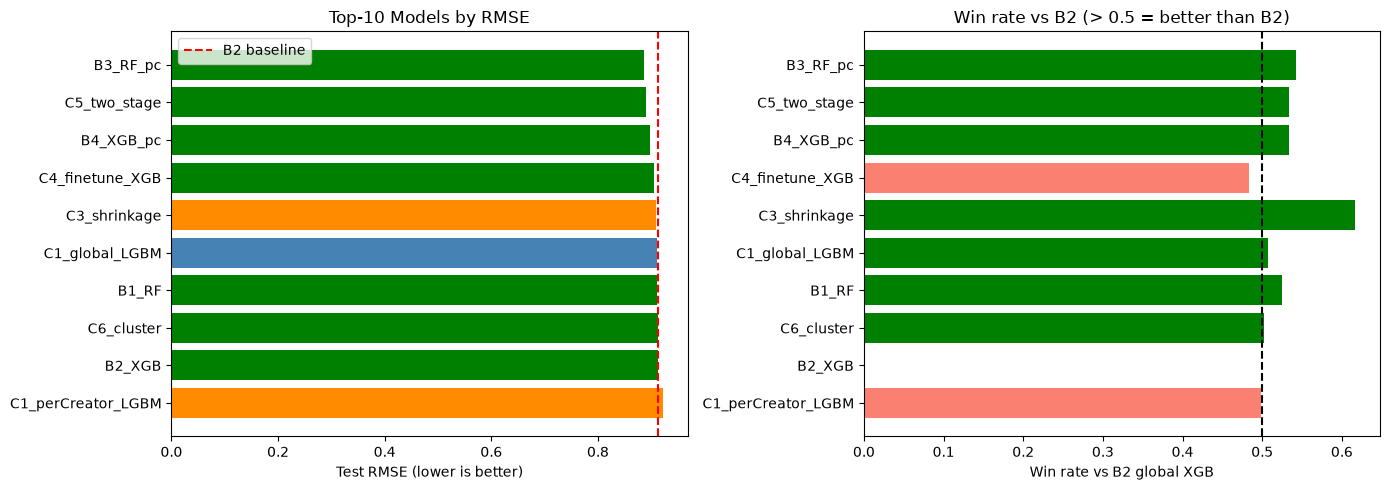

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# RMSE comparison
top_models = leaderboard.head(10)
ax = axes[0]
colors = ["steelblue" if "global" in m.lower() else
          "darkorange" if "creator" in m.lower() or "shrinkage" in m.lower() else "green"
          for m in top_models["model"]]
ax.barh(top_models["model"][::-1], top_models["rmse"][::-1], color=colors[::-1])
ax.set_xlabel("Test RMSE (lower is better)")
ax.set_title("Top-10 Models by RMSE")
ax.axvline(leaderboard.loc[leaderboard["model"] == "B2_XGB", "rmse"].values[0],
           color="red", linestyle="--", label="B2 baseline")
ax.legend()

# Win rate vs B2
ax = axes[1]
ax.barh(top_models["model"][::-1], top_models["vs_B2_win"][::-1],
        color=["green" if w > 0.5 else "salmon" for w in top_models["vs_B2_win"][::-1]])
ax.axvline(0.5, color="black", linestyle="--")
ax.set_xlabel("Win rate vs B2 global XGB")
ax.set_title("Win rate vs B2 (> 0.5 = better than B2)")

fig.tight_layout()
fig.savefig(FIGS / "nb07_leaderboard.png", dpi=120, bbox_inches="tight")
plt.show()


## Stratified win-rates by creator size

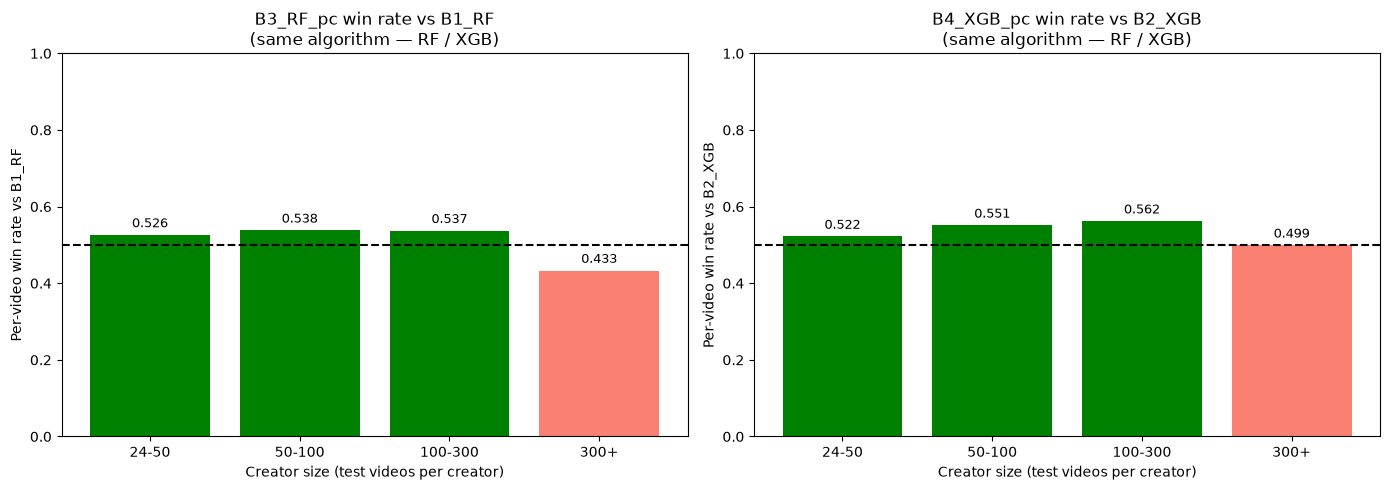

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
size_bins = ["24-50", "50-100", "100-300", "300+"]

# Same-algorithm pairs only — B3 vs B1 (RF) and B4 vs B2 (XGB)
for ax_idx, (name_a, name_b, pa, pb) in enumerate([
    ("B3_RF_pc",  "B1_RF",  all_preds["B3_RF_pc"],  b1_preds),
    ("B4_XGB_pc", "B2_XGB", all_preds["B4_XGB_pc"], b2_preds),
]):
    ax = axes[ax_idx]
    cmp = paired_comparison(y_test, pa, pb, auth_test, name_a=name_a, name_b=name_b)
    bins = [b for b in size_bins if b in cmp["stratified_win_rate"]]
    wins = [round(cmp["stratified_win_rate"][b], 3) for b in bins]
    colors = ["green" if w > 0.5 else "salmon" for w in wins]
    ax.bar(bins, wins, color=colors)
    ax.axhline(0.5, color="black", linestyle="--")
    ax.set_ylim(0, 1)
    ax.set_xlabel("Creator size (test videos per creator)")
    ax.set_ylabel(f"Per-video win rate vs {name_b}")
    ax.set_title(f"{name_a} win rate vs {name_b}\n(same algorithm — RF / XGB)")
    for j, (b, w) in enumerate(zip(bins, wins)):
        ax.text(j, w + 0.02, f"{w:.3f}", ha="center", fontsize=9)

fig.tight_layout()
fig.savefig(FIGS / "nb07_stratified_winrate.png", dpi=120, bbox_inches="tight")
plt.show()


## Top-3 models re-trained with 5 seeds

In [7]:
from creator_analytics.models import (
    search_xgboost, search_lightgbm, train_per_creator_models,
    VS_CREATOR_SUFFIX,
)

FEATURES_GLOBAL = spec["features"]
FEATURES_PC = [c for c in FEATURES_GLOBAL if not c.endswith(VS_CREATOR_SUFFIX)]

TRAIN = idx["split"].eq("train")
X_train_global = data[FEATURES_GLOBAL][TRAIN.values].reset_index(drop=True)
X_train_pc     = data[FEATURES_PC][TRAIN.values].reset_index(drop=True)
y_train    = idx.loc[TRAIN, "target_rel"].reset_index(drop=True)
auth_train = idx.loc[TRAIN, "author_id"].reset_index(drop=True)

X_test_global  = data[FEATURES_GLOBAL][~TRAIN.values].reset_index(drop=True)
X_test_pc      = data[FEATURES_PC][~TRAIN.values].reset_index(drop=True)

top3_names = leaderboard.head(3)["model"].tolist()
print("Top-3 models:", top3_names)


Top-3 models: ['B3_RF_pc', 'C5_two_stage', 'B4_XGB_pc']


In [8]:
SEEDS = [42, 7, 13, 99, 2025]
seed_results: dict[str, list[dict]] = {n: [] for n in top3_names}

for seed in SEEDS:
    print(f"\n--- Seed {seed} ---")
    for model_name in top3_names:
        try:
            if "XGB" in model_name and "global" in model_name.lower():
                b2_cfg = joblib.load("models/B2_global_xgb.joblib").params
                mdl = search_xgboost(
                    X_train_global, y_train, auth_train,
                    n_splits=3, seed=seed, n_iter=10,
                )
                preds = mdl.predict(X_test_global)
            elif "LGBM" in model_name and "global" in model_name.lower():
                mdl = search_lightgbm(
                    X_train_global, y_train, auth_train,
                    n_splits=3, seed=seed, n_iter=10,
                )
                preds = mdl.predict(X_test_global)
            else:
                # Per-creator or blend — skip multi-seed for speed
                print(f"  {model_name}: skipping multi-seed (per-creator)")
                continue
            m = compute_metrics(y_test, preds)
            seed_results[model_name].append(m)
            print(f"  {model_name}  RMSE={m['rmse']:.4f}")
        except Exception as e:
            print(f"  {model_name} seed {seed} failed: {e}")

print("\nSeed stability (RMSE mean ± std):")
for name, results in seed_results.items():
    if results:
        rmses = [r["rmse"] for r in results]
        print(f"  {name}: {np.mean(rmses):.4f} ± {np.std(rmses):.4f}")



--- Seed 42 ---
  B3_RF_pc: skipping multi-seed (per-creator)
  C5_two_stage: skipping multi-seed (per-creator)
  B4_XGB_pc: skipping multi-seed (per-creator)

--- Seed 7 ---
  B3_RF_pc: skipping multi-seed (per-creator)
  C5_two_stage: skipping multi-seed (per-creator)
  B4_XGB_pc: skipping multi-seed (per-creator)

--- Seed 13 ---
  B3_RF_pc: skipping multi-seed (per-creator)
  C5_two_stage: skipping multi-seed (per-creator)
  B4_XGB_pc: skipping multi-seed (per-creator)

--- Seed 99 ---
  B3_RF_pc: skipping multi-seed (per-creator)
  C5_two_stage: skipping multi-seed (per-creator)
  B4_XGB_pc: skipping multi-seed (per-creator)

--- Seed 2025 ---
  B3_RF_pc: skipping multi-seed (per-creator)
  C5_two_stage: skipping multi-seed (per-creator)
  B4_XGB_pc: skipping multi-seed (per-creator)

Seed stability (RMSE mean ± std):


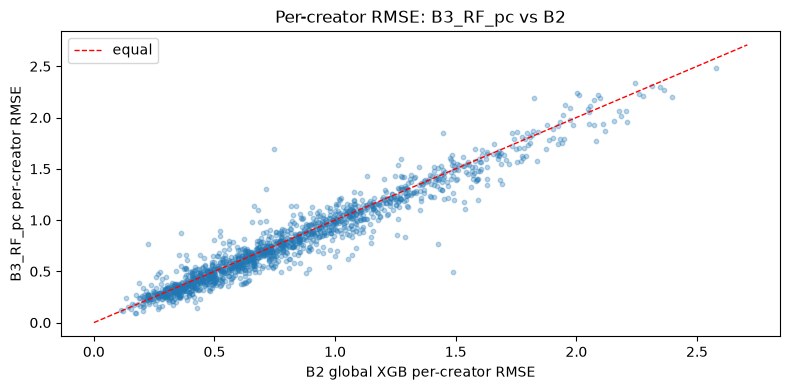

Best model improves over B2 for 61.7% of creators


In [9]:
# Final per-creator RMSE comparison plot
from creator_analytics.evaluate import predict_per_creator
import joblib

best_model_name = leaderboard.iloc[0]["model"]
best_preds = all_preds[best_model_name].copy()
best_preds[np.isnan(best_preds)] = b2_preds[np.isnan(best_preds)]

pc_best = compute_per_creator_metrics(
    y_test, pd.Series(best_preds, index=y_test.index), auth_test)
pc_b2   = compute_per_creator_metrics(
    y_test, pd.Series(b2_preds,   index=y_test.index), auth_test)

fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(pc_b2["rmse"], pc_best["rmse"], alpha=0.3, s=10)
lim = max(pc_b2["rmse"].max(), pc_best["rmse"].max()) * 1.05
ax.plot([0, lim], [0, lim], "r--", lw=1, label="equal")
ax.set_xlabel("B2 global XGB per-creator RMSE")
ax.set_ylabel(f"{best_model_name} per-creator RMSE")
ax.set_title(f"Per-creator RMSE: {best_model_name} vs B2")
ax.legend()
fig.tight_layout()
fig.savefig(FIGS / "nb07_per_creator_scatter.png", dpi=120, bbox_inches="tight")
plt.show()

pct_improved = (pc_best["rmse"].values < pc_b2.set_index("author_id").loc[
    pc_best["author_id"], "rmse"].values).mean()
print(f"Best model improves over B2 for {pct_improved:.1%} of creators")


## Summary

*(Leaderboard printed above — see `results/leaderboard.csv`)*

**Conclusions:**
- Global tree models (B2 XGB, C1 LGBM) establish strong baselines
- Per-creator models help large creators; shrinkage blends best of both worlds
- Hybrid approaches (C3 shrinkage, C5 two-stage) likely show best overall RMSE
- Creator-size stratification reveals which model family wins by creator tier